# 01 - Exploratory data analysis

Chest X-Ray Images (Pneumonia), AIE231 course project.

This notebook only looks at the data. All loading and splitting code lives in `src/data.py`, the notebook just calls it.

**Task recap**

| | |
|---|---|
| Input | one chest X-ray, resized to 224 x 224 x 3, pixels scaled to [0, 1] |
| Output | probability that the X-ray shows pneumonia (one sigmoid unit) |
| Loss | binary cross-entropy, with class weights for the imbalance |
| Primary metric | recall on PNEUMONIA (a missed pneumonia is the worst error) |
| Supporting metrics | macro-F1 and ROC-AUC, so a model can't win by calling everything pneumonia |

In [1]:
import sys
sys.path.append("..")  # so we can import from src/

from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

from src.data import build_index, find_data_dir, remove_duplicates, load_split, CLASSES

DATA_DIR = find_data_dir()  # uses CXR_DATA_DIR or the Kaggle input folder
print("dataset folder found:", sorted(p.name for p in DATA_DIR.iterdir()))

dataset folder found: ['__MACOSX', 'chest_xray', 'test', 'train', 'val']


## 1. What is in the folders

In [2]:
raw = build_index(DATA_DIR)  # one row per image, also hashes every file (takes a few seconds)
print("total images:", len(raw))
pd.crosstab(raw["official_split"], raw["class_name"], margins=True)

total images: 5856


class_name,NORMAL,PNEUMONIA,All
official_split,,,
test,234,390,624
train,1341,3875,5216
val,8,8,16
All,1583,4273,5856


The official validation folder has only 16 images (8 per class). That is far too small to choose models or tune a threshold with, one image changes the accuracy by 6 points. So we will pool everything and make our own split (section 6).

## 2. Class balance

class_name
PNEUMONIA    4273
NORMAL       1583
PNEUMONIA : NORMAL = 2.70 : 1   (73.0% pneumonia)


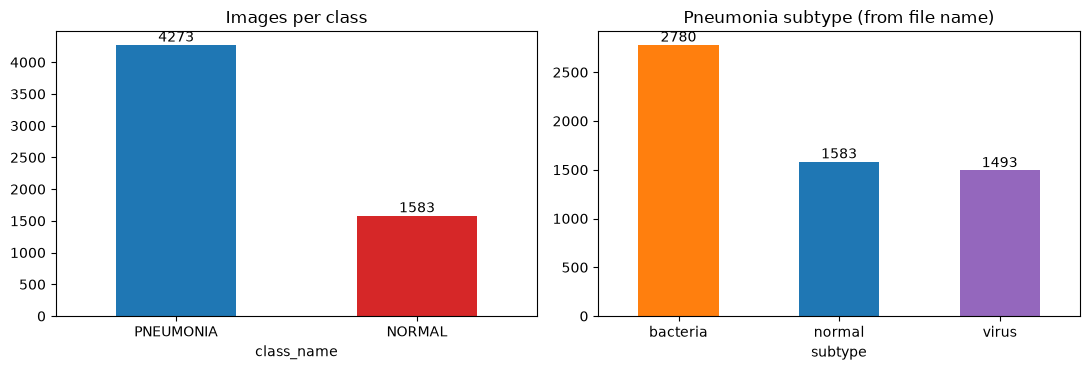

In [3]:
counts = raw["class_name"].value_counts()
ratio = counts["PNEUMONIA"] / counts["NORMAL"]
print(counts.to_string())
print(f"PNEUMONIA : NORMAL = {ratio:.2f} : 1   ({counts['PNEUMONIA'] / len(raw):.1%} pneumonia)")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
counts.plot.bar(ax=axes[0], color=["tab:blue", "tab:red"], rot=0, title="Images per class")
raw["subtype"].value_counts().plot.bar(ax=axes[1], color=["tab:orange", "tab:blue", "tab:purple"], rot=0,
                                         title="Pneumonia subtype (from file name)")
for ax in axes:
    for p in ax.patches:
        ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.tight_layout()
plt.show()

About 73% of the images are pneumonia. A model that always says PNEUMONIA already gets about 73% accuracy and 100% pneumonia recall, which is why accuracy alone is useless here and why we also track NORMAL recall, macro-F1 and ROC-AUC. Pneumonia images are also split into bacterial and viral cases. We only predict normal vs pneumonia, but we keep the subtype for error analysis later.

## 3. Image size and colour mode

In [4]:
sizes = []
for p in raw["path"]:
    with Image.open(DATA_DIR / p) as im:  # only reads the header, fast
        sizes.append((im.width, im.height, im.mode))
raw[["width", "height", "mode"]] = pd.DataFrame(sizes, index=raw.index)
raw["aspect"] = raw["width"] / raw["height"]

print(raw.groupby("class_name")[["width", "height", "aspect"]].describe().T.round(2))
print()
print(pd.crosstab(raw["mode"], raw["class_name"]))

class_name     NORMAL  PNEUMONIA
width  count  1583.00    4273.00
       mean   1686.38    1195.07
       std     305.32     285.15
       min     912.00     384.00
       25%    1472.00    1000.00
       50%    1654.00    1160.00
       75%    1848.00    1360.00
       max    2916.00    2772.00
height count  1583.00    4273.00
       mean   1378.65     819.55
       std     343.02     270.86
       min     496.00     127.00
       25%    1140.00     640.00
       50%    1323.00     776.00
       75%    1554.00     960.00
       max    2713.00    2304.00
aspect count  1583.00    4273.00
       mean      1.25       1.51
       std       0.15       0.25
       min       0.88       0.84
       25%       1.15       1.36
       50%       1.23       1.49
       75%       1.34       1.65
       max       2.11       3.38

class_name  NORMAL  PNEUMONIA
mode                         
L             1583       3990
RGB              0        283


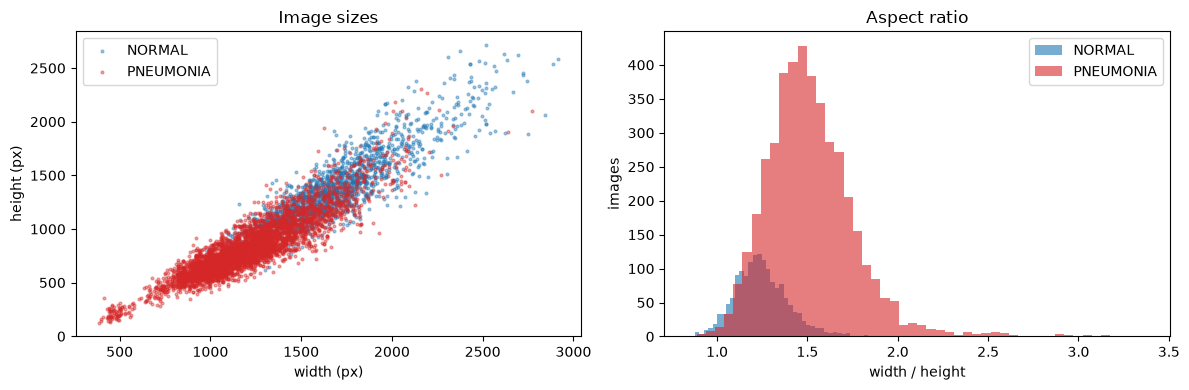

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for cls, color in zip(CLASSES, ["tab:blue", "tab:red"]):
    part = raw[raw["class_name"] == cls]
    axes[0].scatter(part["width"], part["height"], s=4, alpha=0.4, color=color, label=cls)
    axes[1].hist(part["aspect"], bins=50, alpha=0.6, color=color, label=cls)
axes[0].set(xlabel="width (px)", ylabel="height (px)", title="Image sizes")
axes[1].set(xlabel="width / height", ylabel="images", title="Aspect ratio")
axes[0].legend(); axes[1].legend()
plt.tight_layout()
plt.show()

Two things here surprised us.

1. **Size and shape depend on the class.** NORMAL images are much bigger (about 1690 x 1380 on average) than PNEUMONIA images (about 1200 x 820), and PNEUMONIA images are wider for their height (aspect ratio 1.51 vs 1.25). Looking at the samples below, the pneumonia X-rays seem to be cropped tighter around the chest. This is not medical, it is how the images were collected, and a model could use it as a shortcut.
2. **All 283 RGB files are PNEUMONIA.** No NORMAL image is RGB. If we kept the colour channels, "has colour" would be a perfect pneumonia signal for those files.

The next cell measures how strong the size shortcut is.

In [6]:
from sklearn.metrics import roc_auc_score

# AUC of a single number used as a score: 0.5 = useless, 1.0 = separates the classes perfectly.
# Minus sign because smaller images are more often PNEUMONIA.
for name, score in [("height", -raw["height"]), ("width", -raw["width"]), ("aspect ratio", raw["aspect"])]:
    print(f"AUC of {name:12s} alone: {roc_auc_score(raw['label'], score):.3f}")

AUC of height       alone: 0.915
AUC of width        alone: 0.889
AUC of aspect ratio alone: 0.840


Image height alone already separates the classes with an AUC of about 0.92, without looking at the lungs at all. Resizing every image to 224 x 224 removes the absolute size, but not the shape: a wide image gets squeezed more, so the aspect ratio (AUC about 0.84 alone) is still hidden in the resized picture. We can't fully remove that without cutting off parts of the lungs, so we keep the plain resize and **check it in the error analysis** (does the model fail more on NORMAL images that are unusually wide, or pneumonia images that are unusually square?).

For the colour problem the fix is easy: the loader reads every file as grayscale and then copies it to 3 channels (VGG16 needs 3), so colour can't reach the model.

## 4. Duplicates

In [7]:
dup_groups = raw[raw.duplicated("md5", keep=False)].groupby("md5")
print("files that have an exact copy somewhere:", raw.duplicated("md5", keep=False).sum())
print("extra copies (would be removed):", raw.duplicated("md5").sum())
print("copies with different labels:", sum(g["label"].nunique() > 1 for _, g in dup_groups))
if len(dup_groups):
    display(raw[raw.duplicated("md5", keep=False)].sort_values("md5")[["path", "class_name", "patient"]].head(10))

files that have an exact copy somewhere: 62
extra copies (would be removed): 32
copies with different labels: 0


,path,class_name,patient
5371,test/NORMAL/NORMAL2-IM-0246-0001-0002.jpeg,NORMAL,NORMAL2-IM-0246
5370,test/NORMAL/NORMAL2-IM-0246-0001-0001.jpeg,NORMAL,NORMAL2-IM-0246
2674,train/PNEUMONIA/person1619_bacteria_4268.jpeg,PNEUMONIA,person1619
2673,train/PNEUMONIA/person1619_bacteria_4267.jpeg,PNEUMONIA,person1619
2068,train/PNEUMONIA/person1349_bacteria_3436.jpeg,PNEUMONIA,person1349
2069,train/PNEUMONIA/person1349_bacteria_3437.jpeg,PNEUMONIA,person1349
2372,train/PNEUMONIA/person1481_bacteria_3867.jpeg,PNEUMONIA,person1481
2371,train/PNEUMONIA/person1481_bacteria_3866.jpeg,PNEUMONIA,person1481
3494,train/PNEUMONIA/person357_virus_734.jpeg,PNEUMONIA,person357
3495,train/PNEUMONIA/person357_virus_735.jpeg,PNEUMONIA,person357


Exact duplicates are found by hashing the file bytes (MD5). There are 32 extra copies, almost all of them the same X-ray saved twice under two image numbers of the same patient, and none with conflicting labels. If a duplicate pair ended up in train and test, the test score would be inflated, so `remove_duplicates` keeps one copy (and would drop both if the labels disagreed). 5,824 images are left.

## 5. Patients

patients: 3118
images per patient: {'count': 3118.0, 'mean': 1.88, 'std': 1.77, 'min': 1.0, '25%': 1.0, '50%': 1.0, '75%': 2.0, 'max': 31.0}
patients with more than one image: 1185 (67.0% of all images)
patient ids that appear in BOTH the official train and test folders: 170


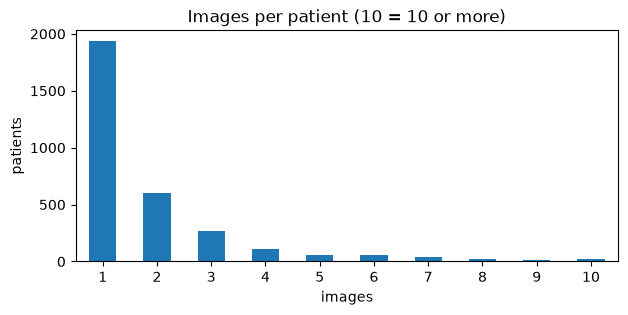

In [8]:
per_patient = raw.groupby("patient").size()
print("patients:", per_patient.size)
print("images per patient:", per_patient.describe().round(2).to_dict())
print("patients with more than one image:", (per_patient > 1).sum(),
      f"({raw['patient'].isin(per_patient[per_patient > 1].index).mean():.1%} of all images)")

in_train = set(raw.loc[raw["official_split"] == "train", "patient"])
in_test = set(raw.loc[raw["official_split"] == "test", "patient"])
print("patient ids that appear in BOTH the official train and test folders:", len(in_train & in_test))

per_patient.clip(upper=10).value_counts().sort_index().plot.bar(rot=0, figsize=(7, 3),
    title="Images per patient (10 = 10 or more)")
plt.xlabel("images"); plt.ylabel("patients")
plt.show()

About two thirds of all images belong to a patient with more than one X-ray (one patient has 31). Two X-rays of the same child look much more alike than X-rays of two different children, so if one is in train and the other in test, the test score measures memory, not generalisation. This is the leakage the spec warns about ("if several samples come from the same person, keep them in the same split"). We split by patient.

Note: the patient id comes from the file name. 170 ids (like `person1`) appear in both the official train and test folders. The Mendeley page says train and test are independent patients, so these are probably numbers that restart in each folder, not the same child. We still treat equal ids as one patient: at worst a group is a bit bigger than needed, which can't cause leakage.

## 6. Pixel intensities

             mean           std       
             mean    std   mean    std
class_name                            
NORMAL      0.486  0.055  0.239  0.023
PNEUMONIA   0.476  0.075  0.219  0.037


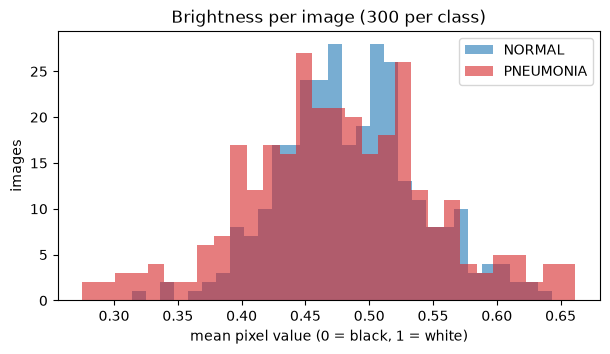

In [9]:
sample = raw.groupby("class_name").sample(300, random_state=42)
stats = []
for p, cls in zip(sample["path"], sample["class_name"]):
    with Image.open(DATA_DIR / p) as im:
        a = np.asarray(im.convert("L").resize((128, 128)), dtype=np.float32) / 255.0
    stats.append((cls, a.mean(), a.std()))
stats = pd.DataFrame(stats, columns=["class_name", "mean", "std"])
print(stats.groupby("class_name").agg(["mean", "std"]).round(3))

fig, ax = plt.subplots(figsize=(7, 3.5))
for cls, color in zip(CLASSES, ["tab:blue", "tab:red"]):
    ax.hist(stats.loc[stats["class_name"] == cls, "mean"], bins=30, alpha=0.6, color=color, label=cls)
ax.set(xlabel="mean pixel value (0 = black, 1 = white)", ylabel="images", title="Brightness per image (300 per class)")
ax.legend()
plt.show()

Pixel values are 0 to 255 in every file, so we scale with a fixed /255 to get [0, 1]. Average brightness is almost the same for both classes (about 0.49 vs 0.48). Nothing is fitted on the data, so this step can't leak test information. The brightness ranges of the two classes overlap a lot, so a simple brightness rule will not separate them, the model has to look at patterns (opacity in the lungs).

## 7. Sample images

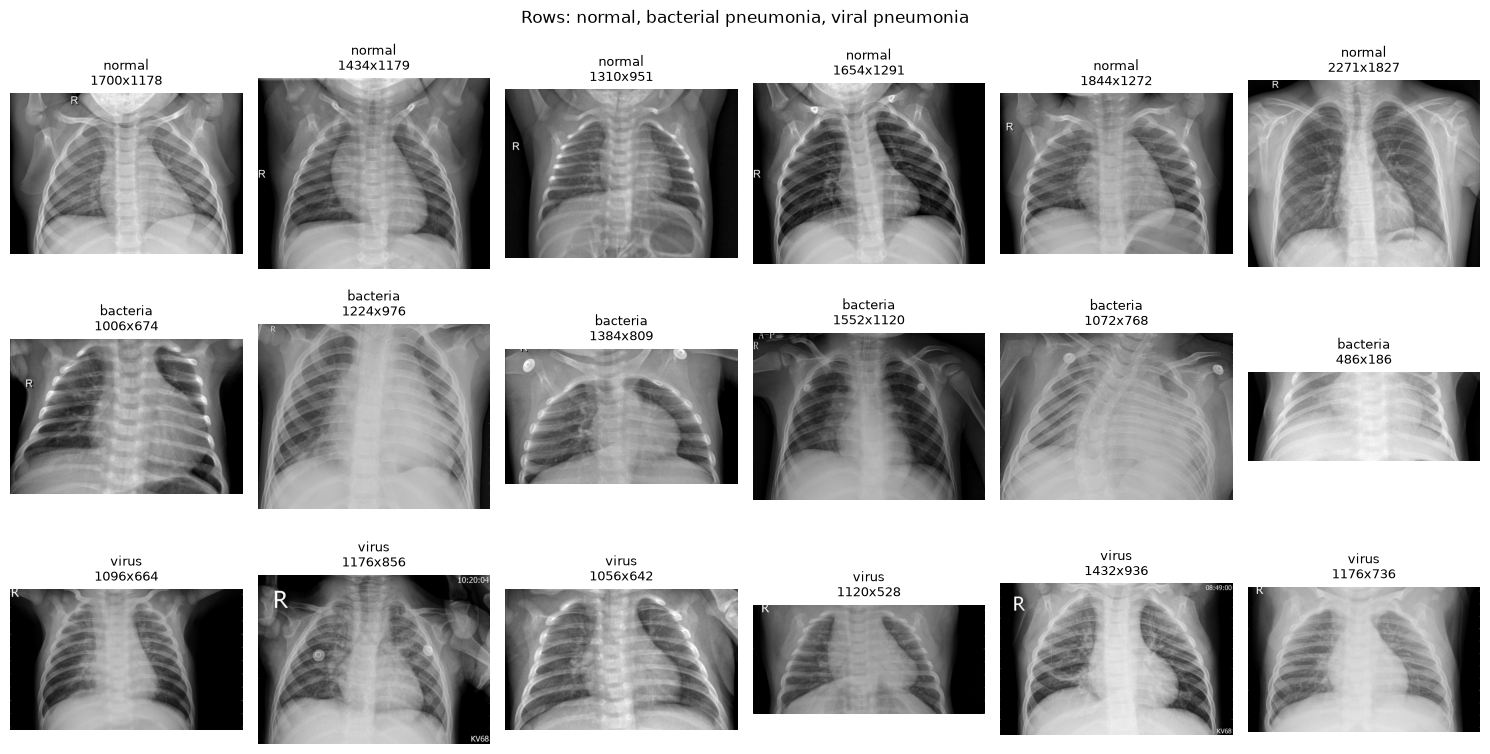

In [10]:
fig, axes = plt.subplots(3, 6, figsize=(15, 8))
picks = pd.concat([
    raw[raw["subtype"] == "normal"].sample(6, random_state=1),
    raw[raw["subtype"] == "bacteria"].sample(6, random_state=1),
    raw[raw["subtype"] == "virus"].sample(6, random_state=1),
])
for ax, (_, row) in zip(axes.ravel(), picks.iterrows()):
    with Image.open(DATA_DIR / row["path"]) as im:
        ax.imshow(im.convert("L"), cmap="gray")
    ax.set_title(f"{row['subtype']}\n{row['width']}x{row['height']}", fontsize=9)
    ax.axis("off")
plt.suptitle("Rows: normal, bacterial pneumonia, viral pneumonia")
plt.tight_layout()
plt.show()

Things we noticed by looking:

- Many images have a burned-in "R" marker, and some have a timestamp or text like "KV68" in the corner. Some show ECG electrodes or clips. These are not part of the lungs, a CNN might still pick them up.
- The NORMAL images often show more of the neck and shoulders, the pneumonia ones are cropped tighter around the chest (this matches the size difference in section 3).
- Some pneumonia cases are easy to see (a dense white area, often bacterial), others are subtle and spread out (often viral). We expect most errors on subtle cases.
- These are children (the source says pediatric patients aged 1 to 5), so the model should not be expected to work on adults.

## 8. Our split (made by `python -m src.data`)

In [11]:
split = load_split("../data/split.csv")  # load_split runs the leakage check again
table = pd.crosstab(split["split"], split["class_name"], margins=True)
table["% pneumonia"] = (100 * table["PNEUMONIA"] / table["All"]).round(1)
table["% of data"] = (100 * table["All"] / len(split)).round(1)
print(table.loc[["train", "val", "test", "All"]])
print("patients per split:", split.groupby("split")["patient"].nunique().to_dict())
print("leakage check passed: no patient and no file is in two splits")

class_name  NORMAL  PNEUMONIA   All  % pneumonia  % of data
split                                                      
train         1105       2972  4077         72.9       70.0
val            237        636   873         72.9       15.0
test           237        637   874         72.9       15.0
All           1579       4245  5824         72.9      100.0
patients per split: {'test': 464, 'train': 2185, 'val': 468}
leakage check passed: no patient and no file is in two splits


## 9. Findings and what we do about them

| # | Finding | Decision |
|---|---------|----------|
| 1 | 73% PNEUMONIA vs 27% NORMAL (about 2.7 : 1) | Class weights in the loss (n / (2 n_c)). Report per-class recall, macro-F1 and ROC-AUC, never accuracy alone |
| 2 | Missing pneumonia costs much more than a false alarm | Primary metric: recall on PNEUMONIA. Later we can lower the decision threshold, chosen on validation only |
| 3 | Official val folder has only 16 images | Pool all folders and re-split 70 / 15 / 15, stratified by class |
| 4 | Many patients have several X-rays | Split grouped by patient (StratifiedGroupKFold), checked by `check_no_leakage` |
| 5 | 32 exact duplicate files (same X-ray saved twice) | Remove by MD5 hash before splitting |
| 6 | Image size depends on the class (height alone: AUC about 0.92) | Resize every image to 224 x 224, so absolute size is gone |
| 7 | Aspect ratio also depends on the class (AUC about 0.84) and survives the resize as stretching | Keep the plain resize (cropping would cut lungs), check this shortcut in the error analysis |
| 8 | All 283 RGB files are PNEUMONIA | Read every file as grayscale, then copy to 3 channels for VGG16 |
| 9 | Pixel range 0 to 255, brightness overlaps between classes | Fixed /255 scaling, nothing fitted, no leakage |
| 10 | Framing, rotation and contrast differ, burned-in text and markers | Training-only augmentation: small rotation, zoom, shift, contrast. No horizontal flip (heart is on the left) |
| 11 | Pediatric patients only | State it as a limitation, the model is not for adults and is not a diagnostic tool |